# Baseline Test with Stable Diffusion 1.5
This notebook runs the base Stable Diffusion model on 5 pixel art prompts before any fine-tuning. The results show how a general model handles pixel art.

## 1. Setup

In [ ]:
# 第1格：检查GPU，安装生成图片要用的工具包
!nvidia-smi
!pip install -q diffusers transformers accelerate

import torch
print("GPU available:", torch.cuda.is_available())

Wed Nov  4 18:21:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Connect Google Drive

In [ ]:
# 第2格：连接Google Drive，创建保存测试图片的文件夹
from google.colab import drive
drive.mount("/content/drive")

import os
# Change this to your own project folder before running
PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project"
OUT_DIR = os.path.join(PROJECT_DIR, "results", "baseline")  # folder for baseline images
os.makedirs(OUT_DIR, exist_ok=True)
print("Images will be saved to:", OUT_DIR)

Mounted at /content/drive
Images will be saved to: /content/drive/MyDrive/Colab Notebooks/IE 7615 深度学习/P2 Generative Project/results/baseline


## 3. Load the base model

In [ ]:
# 第3格：下载并加载基础版Stable Diffusion 1.5模型
from diffusers import StableDiffusionPipeline

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=torch.float16)  # half precision saves memory
pipe = pipe.to("cuda")  # move model to GPU
print("Model loaded:", MODEL_ID)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Model loaded: stable-diffusion-v1-5/stable-diffusion-v1-5


## 4. Generate baseline images

In [ ]:
# 第4格：用5个像素画提示词生成测试图片，并保存到Drive
PROMPTS = [
    "pixel art of a red apple",
    "pixel art of a knight holding a sword",
    "pixel art of a small green frog",
    "pixel art of a blue potion bottle",
    "pixel art of a wooden treasure chest",
]
SEED = 42  # fixed seed so results can be repeated

images = []
for i, prompt in enumerate(PROMPTS):
    generator = torch.Generator("cuda").manual_seed(SEED)  # same start noise for every prompt
    image = pipe(prompt, num_inference_steps=30, guidance_scale=7.5, generator=generator).images[0]
    path = os.path.join(OUT_DIR, f"baseline_{i+1}.png")
    image.save(path)
    images.append(image)
    print(f"Saved image {i+1}: {prompt}")

  0%|          | 0/30 [00:00<?, ?it/s]

Saved image 1: pixel art of a red apple


  0%|          | 0/30 [00:00<?, ?it/s]

Saved image 2: pixel art of a knight holding a sword


  0%|          | 0/30 [00:00<?, ?it/s]

Saved image 3: pixel art of a small green frog


  0%|          | 0/30 [00:00<?, ?it/s]

Saved image 4: pixel art of a blue potion bottle


  0%|          | 0/30 [00:00<?, ?it/s]

Saved image 5: pixel art of a wooden treasure chest


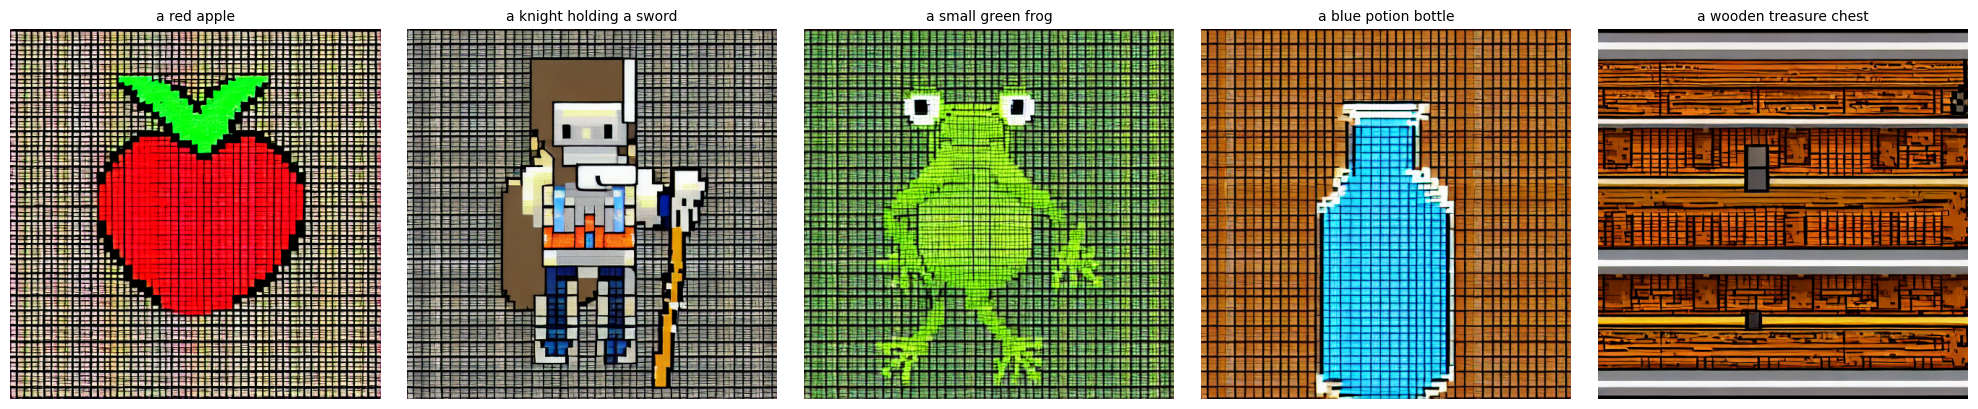

In [ ]:
# 第5格：把5张图排成一排显示，每张图上方写提示词
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, image, prompt in zip(axes, images, PROMPTS):
    ax.imshow(image)
    ax.set_title(prompt.replace("pixel art of ", ""), fontsize=10)  # short title
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "baseline_grid.png"), dpi=100)  # save the grid for the proposal
plt.show()

## 5. Observations

The base model knows the general look of pixel art, but it does not draw real pixel art. It adds grid lines on top of the image instead of using clean blocks of color. The backgrounds are busy, while sprites in our dataset have plain backgrounds. Some objects are wrong. The apple looks like a heart, the sword is in the wrong place, and the treasure chest is missing. The pixel size is not the same across the image and there are too many colors. These problems show why we need to fine-tune the model on a pixel art dataset.